# Fungi Classification using multiple layers of convolution and neural networks
**Name: Samruddhi Talekar**
**Roll No: 409**

## 1. Imports

In [3]:
import os
import shutil
import zipfile
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)


## 2. Dataset

In [2]:
DATASET_ROOT = r"D:\Samm\Bachelors\TY.Dsc\Computer Vision\Assignments\Fungi Assignment\fungi images"

CLASS_NAMES = ["H1", "H2", "H3", "H5", "H6"]

print("Dataset root:", DATASET_ROOT)

Dataset root: D:\Samm\Bachelors\TY.Dsc\Computer Vision\Assignments\Fungi Assignment\fungi images


## 3. Exploring the dataset

Images per class:
  H1: 4404
  H2: 2334
  H3: 819
  H5: 818
  H6: 739
Total images: 9114


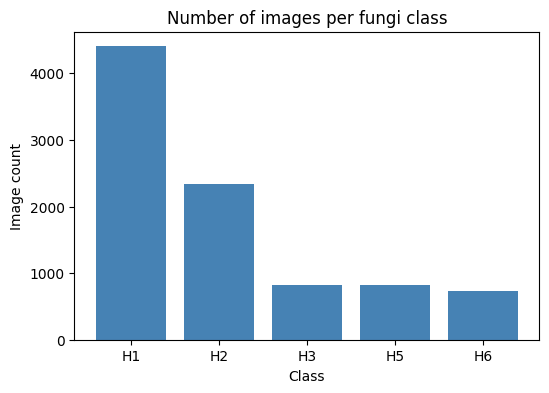

In [4]:
counts = {}
for class_name in CLASS_NAMES:
    class_dir = os.path.join(DATASET_ROOT, class_name)
    counts[class_name] = len(os.listdir(class_dir))

print("Images per class:")
for k, v in counts.items():
    print(f"  {k}: {v}")
print("Total images:", sum(counts.values()))

plt.figure(figsize=(6, 4))
plt.bar(counts.keys(), counts.values(), color="steelblue")
plt.title("Number of images per fungi class")
plt.xlabel("Class")
plt.ylabel("Image count")
plt.show()


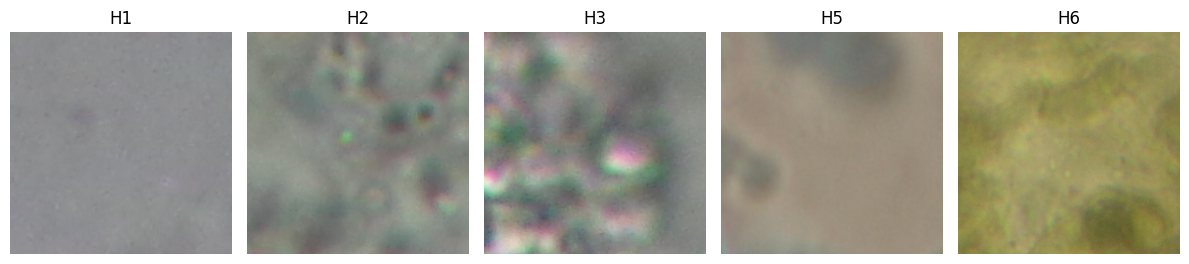

In [5]:
plt.figure(figsize=(12, 6))
for i, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(DATASET_ROOT, class_name)
    sample_file = os.listdir(class_dir)[0]
    img = tf.keras.utils.load_img(os.path.join(class_dir, sample_file))

    plt.subplot(1, len(CLASS_NAMES), i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. Train / Validation / Test Split

In [6]:
filepaths = []
labels = []

for label_index, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(DATASET_ROOT, class_name)
    for fname in os.listdir(class_dir):
        filepaths.append(os.path.join(class_dir, fname))
        labels.append(label_index)

filepaths = np.array(filepaths)
labels = np.array(labels)

train_val_files, test_files, train_val_labels, test_labels = train_test_split(
    filepaths, labels,
    test_size=0.15,
    stratify=labels,
    random_state=SEED
)

train_files, val_files, train_labels, val_labels = train_test_split(
    train_val_files, train_val_labels,
    test_size=0.15 / 0.85,   
    stratify=train_val_labels,
    random_state=SEED
)

print("Train images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))


Train images: 6379
Validation images: 1367
Test images: 1368


## 5. `tf.data` pipelines

In [7]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 64

def load_and_preprocess(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(files, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(files), seed=SEED)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_files, train_labels, shuffle=True)
val_ds = make_dataset(val_files, val_labels)
test_ds = make_dataset(test_files, test_labels)


## 6. Class imbalance

In [8]:
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights = dict(enumerate(class_weight_values))
print("Class weights:", class_weights)


Class weights: {0: np.float64(0.4138177100227052), 1: np.float64(0.7807833537331701), 2: np.float64(2.2265270506108203), 3: np.float64(2.2304195804195803), 4: np.float64(2.467698259187621)}


## 7. Data augmentation

In [9]:
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="data_augmentation")


## 8. CNN Model

In [10]:
num_classes = len(CLASS_NAMES)

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Rescaling(1. / 255),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax"),
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 9. Compile the model

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 10. Callbacks

In [12]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_fungi_model.keras", monitor="val_loss", save_best_only=True
    ),
]


## 11. Train the model

In [13]:
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 116ms/step - accuracy: 0.5201 - loss: 1.1854 - val_accuracy: 0.4792 - val_loss: 1.5802 - learning_rate: 0.0010
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.5687 - loss: 0.9477 - val_accuracy: 0.4835 - val_loss: 2.1330 - learning_rate: 0.0010
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 117ms/step - accuracy: 0.5930 - loss: 0.8995 - val_accuracy: 0.4792 - val_loss: 2.5262 - learning_rate: 0.0010
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - accuracy: 0.6220 - loss: 0.8153 - val_accuracy: 0.5099 - val_loss: 1.8293 - learning_rate: 5.0000e-04
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 15s 148ms/step - accuracy: 0.6288 - loss: 0.7927 - val_accuracy: 0.6269 - val_loss: 0.9844 - learning_rate: 5.0000e-04
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 116ms/step - accuracy: 0.6383 - loss: 0.7715 - val_accuracy: 0.6262 - val_loss: 0.8969 - learning_rate: 5.0000e-04
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 12s 118ms/step - a

## 12. Training curves

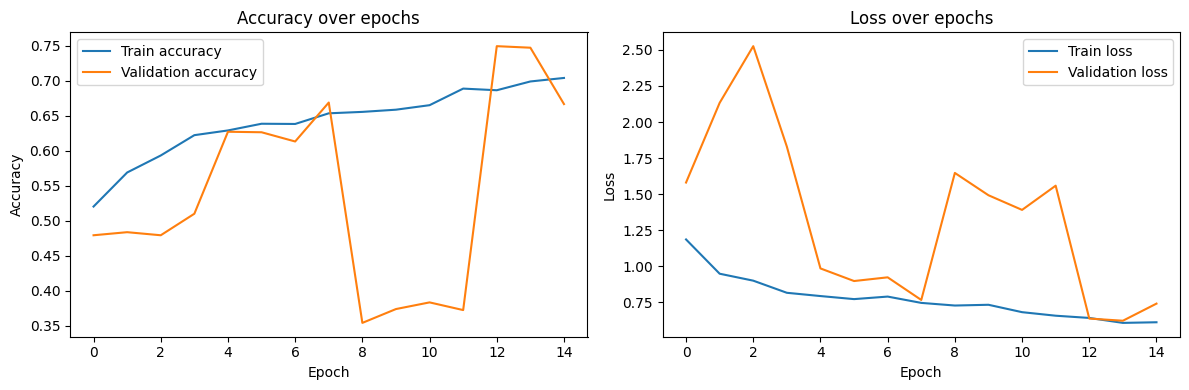

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


## 13. Evaluation on test set

In [15]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

y_true = []
y_pred = []

for images, labels_batch in test_ds:
    predictions = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels_batch.numpy())

print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))


Test loss: 0.6355
Test accuracy: 72.66%

Classification report:

              precision    recall  f1-score   support

          H1       0.80      0.79      0.79       661
          H2       0.59      0.52      0.56       350
          H3       0.59      0.72      0.65       123
          H5       0.76      0.85      0.80       123
          H6       0.82      0.88      0.85       111

    accuracy                           0.73      1368
   macro avg       0.71      0.75      0.73      1368
weighted avg       0.73      0.73      0.72      1368



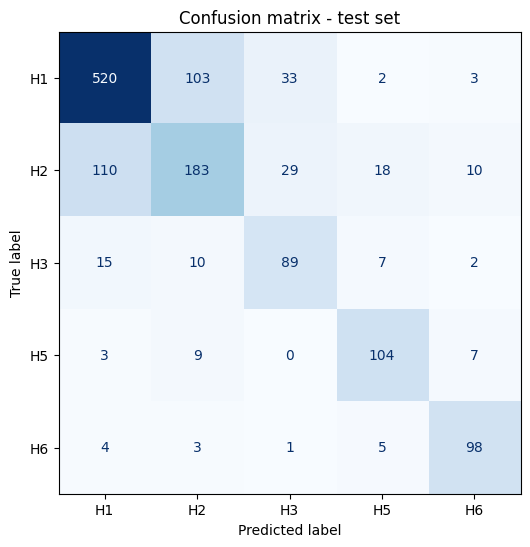

In [16]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion matrix - test set")
plt.show()


## 14. Few individual predictions

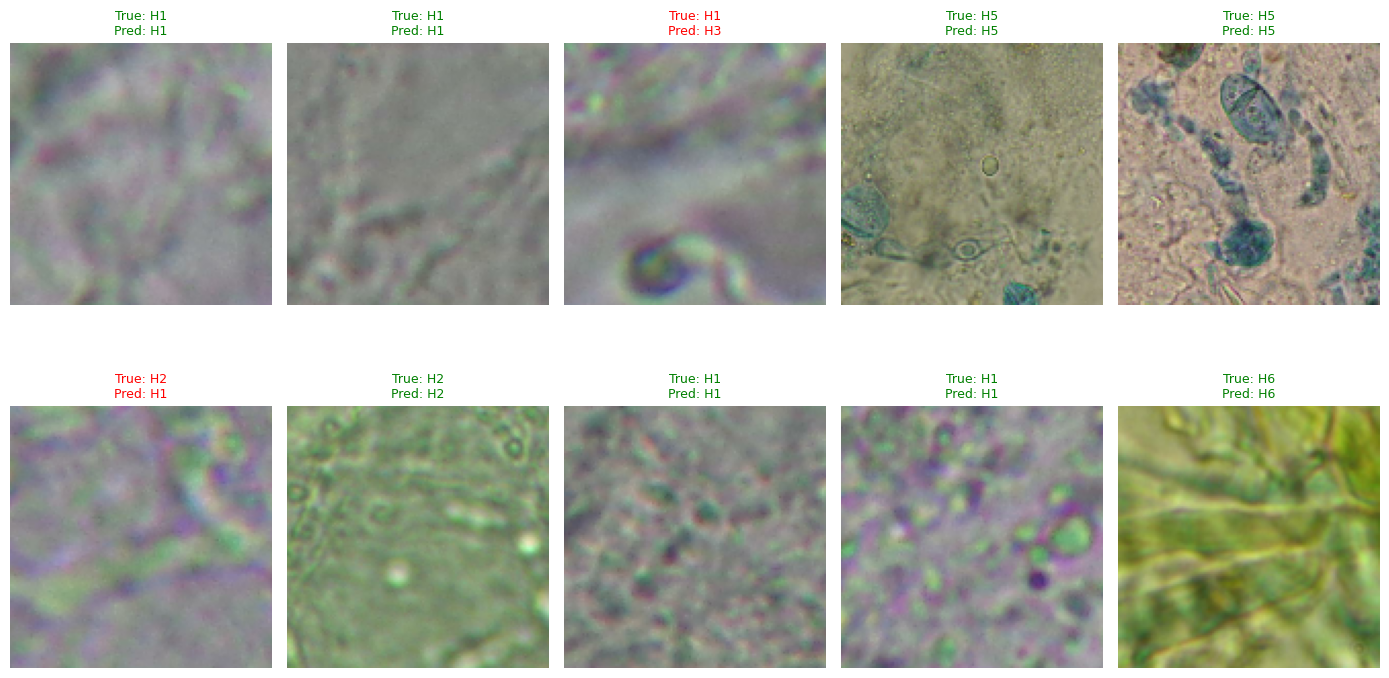

In [17]:
plt.figure(figsize=(14, 8))

for images, labels_batch in test_ds.take(1):
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    for i in range(min(10, images.shape[0])):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_name = CLASS_NAMES[labels_batch[i].numpy()]
        pred_name = CLASS_NAMES[predicted_labels[i]]
        color = "green" if true_name == pred_name else "red"
        plt.title(f"True: {true_name}\nPred: {pred_name}", color=color, fontsize=9)
        plt.axis("off")
    break

plt.tight_layout()
plt.show()


## 15. Save the trained model

In [18]:
import os

MODEL_DIR = r"D:\Samm\Bachelors\TY.Dsc\Computer Vision\Assignments\Fungi Assignment\Saved Model"

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_PATH = os.path.join(MODEL_DIR, "fungi_classifier.keras")

model.save(MODEL_PATH)

print("Model saved at:")
print(MODEL_PATH)

Model saved at:
D:\Samm\Bachelors\TY.Dsc\Computer Vision\Assignments\Fungi Assignment\Saved Model/fungi_classifier.keras
